# Practical 8 — Weather Data Analysis

Create a sample forecast JSON so the notebook works offline. Convert it to a DataFrame, summarize weather and plot patterns. Add an API key only if you want live data.

**Run the cells from top to bottom.** The dataset is generated inside this notebook before the practical begins.

## 1. Install / import requirements

If a package is missing, run `!pip install pandas numpy matplotlib seaborn scikit-learn statsmodels openpyxl requests xgboost` in a notebook cell. Most environments already have the common packages.

In [1]:
from pathlib import Path
Path('data').mkdir(exist_ok=True)


## 2. Create the required dataset

This is the relevant part of `make_data.py`, placed here so the notebook is self-contained.

In [2]:
# Create an offline sample forecast in the same structure as the weather API response.
import json, numpy as np, pandas as pd
rng = np.random.default_rng(42)
times = pd.date_range("2024-10-01", periods=40*4, freq="3h")
items = []
for i, t in enumerate(times):
    items.append({"dt_txt":str(t), "main":{"temp":float(24+6*np.sin(i/8*np.pi/3)+rng.normal(0,1)),
      "humidity":int(rng.integers(40,90))}, "wind":{"speed":float(rng.uniform(1,8))},
      "rain":{"3h":float(rng.choice([0,0,0,rng.uniform(.2,5)]))}})
with open("data/weather_sample.json","w") as f:
    json.dump({"city":{"name":"Pune"},"list":items}, f)
print("Created data/weather_sample.json (offline sample)")


Created data/weather_sample.json (offline sample)


## 3. Practical implementation

The following cells perform the analysis and show the output.

         temp  humidity    wind    rain
count  160.00    160.00  160.00  160.00
mean    24.41     63.81    4.57    0.55
std      4.30     14.20    1.96    1.26
min     15.87     40.00    1.10    0.00
25%     20.58     51.00    2.94    0.00
50%     25.09     63.00    4.58    0.00
75%     28.25     76.00    6.39    0.00
max     32.16     89.00    7.99    4.93
                 temp                            rain      wind
                 mean        max        min       sum      mean
time                                                           
2024-10-01  26.357338  29.172853  22.832122  5.263855  5.763292
2024-10-02  29.630882  30.871429  28.677446  3.283335  3.970026
2024-10-03  27.077868  29.358905  25.083512  0.000000  3.956914
2024-10-04  21.430873  23.616617  19.459877  1.171344  3.023162
2024-10-05  18.108963  20.267150  15.867954  0.000000  4.952510


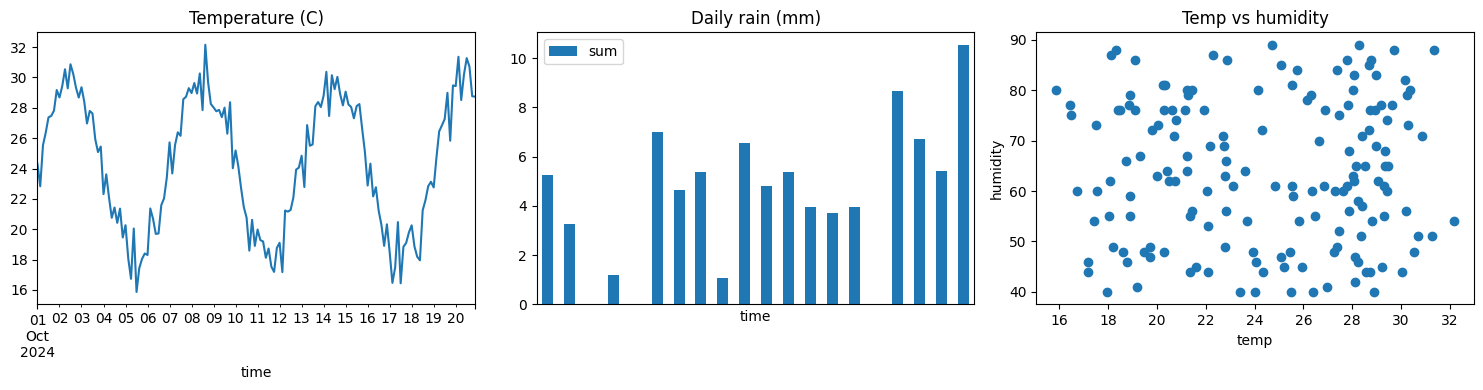

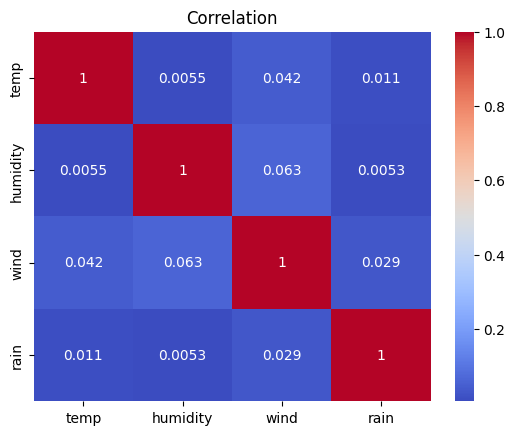

In [3]:
# Get a free key at https://openweathermap.org/api and paste it below.
# With no key, the script uses data/weather_sample.json (same format as the API reply).
import json, requests, pandas as pd, matplotlib.pyplot as plt, seaborn as sns

API_KEY, CITY = "", "Pune"
if API_KEY:
    url = f"https://api.openweathermap.org/data/2.5/forecast?q={CITY}&appid={API_KEY}&units=metric"
    data = requests.get(url).json()
else:
    data = json.load(open("data/weather_sample.json"))

# Extract attributes
df = pd.DataFrame([{"time": x["dt_txt"], "temp": x["main"]["temp"], "humidity": x["main"]["humidity"],
                    "wind": x["wind"]["speed"], "rain": x.get("rain", {}).get("3h", 0)} for x in data["list"]])
df["time"] = pd.to_datetime(df["time"])
df = df.dropna().set_index("time")                       # clean

print(df.describe().round(2))                            # avg / max / min
daily = df.resample("D").agg({"temp": ["mean", "max", "min"], "rain": "sum", "wind": "mean"})
print(daily.head())

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
df.temp.plot(ax=ax[0], title="Temperature (C)")
daily["rain"].plot.bar(ax=ax[1], title="Daily rain (mm)", xticks=[])
ax[2].scatter(df.temp, df.humidity); ax[2].set(title="Temp vs humidity", xlabel="temp", ylabel="humidity")
plt.tight_layout(); plt.show()
sns.heatmap(df.corr(), annot=True, cmap="coolwarm"); plt.title("Correlation"); plt.show()